### Importando as Bibliotecas

In [1]:
import pandas as pd
import numpy as np

import warnings
warnings.filterwarnings('ignore')

def drop_reset_index(df):
    df = df.dropna()
    df = df.reset_index(drop=True)
    df.index += 1
    return df

def plot_profit_acu(dataframe, title_text):
    dataframe['Profit_acu'] = dataframe.Profit.cumsum()
    n_apostas = dataframe.shape[0]
    profit = round(dataframe.Profit_acu.tail(1).item(), 2)
    ROI = round((dataframe.Profit_acu.tail(1) / n_apostas * 100).item(), 2)
    drawdown = dataframe['Profit_acu'] - dataframe['Profit_acu'].cummax()
    drawdown_maximo = round(drawdown.min(), 2)
    winrate_medio = round((dataframe['Profit'] > 0).mean() * 100, 2)
    desvio_padrao = round(dataframe['Profit'].std(), 2)
    dataframe.Profit_acu.plot(title=title_text, xlabel='Entradas', ylabel='Stakes')
    print("Método:",title_text)
    print("Profit:", profit, "stakes em", n_apostas, "jogos")
    print("ROI:", ROI, "%")
    print("Drawdown Maximo Acumulado:", drawdown_maximo)
    print("Winrate Medio:", winrate_medio, "%")
    print("Desvio Padrao:", desvio_padrao)
    print("")

In [2]:
##### Biblioteca de Machine Learning #####
from sklearn.linear_model import LinearRegression

### Linear Regression

*   Tipo de Modelo: Regressão
*   Funcionamento: y = a0 + a1*x1 + a2*x2 + a3*x3 + ... + an*xn
*   Uso: Prever Valores Contínuos
*   Vantagens: Simplicidade e Facilidade de Interpretação.
*   Desvantagens: Supõe uma relação linear entre as variáveis.






### Importando a Base de Dados

In [3]:
df = pd.read_csv('https://github.com/futpythontrader/YouTube/raw/main/Bases_de_Dados/Betfair/Base_de_Dados_Betfair_Exchange_Back_Lay.csv')

df = df[['Date','Time','League','Home','Away','Goals_H','Goals_A','Goals_Min_H','Goals_Min_A',
         'Odd_H_Back','Odd_H_Lay','Odd_A_Back','Odd_A_Lay','Odd_D_Back','Odd_D_Lay',
         'Odd_Over25_FT_Back','Odd_Over25_FT_Lay','Odd_Under25_FT_Back','Odd_Under25_FT_Lay',
         'Odd_BTTS_Yes_Back','Odd_BTTS_Yes_Lay','Odd_BTTS_No_Back','Odd_BTTS_No_Lay',
         'Odd_CS_0x0_Back','Odd_CS_0x0_Lay','Odd_CS_0x1_Back','Odd_CS_0x1_Lay','Odd_CS_1x0_Back','Odd_CS_1x0_Lay']]
df.columns = ['Date','Time','League','Home','Away','Goals_H','Goals_A','Goals_Min_H','Goals_Min_A',
              'Odd_H','Odd_H_Lay','Odd_A','Odd_A_Lay','Odd_D','Odd_D_Lay',
              'Odd_Over25','Odd_Over25_FT_Lay','Odd_Under25','Odd_Under25_FT_Lay',
              'Odd_BTTS_Yes','Odd_BTTS_Yes_Lay','Odd_BTTS_No','Odd_BTTS_No_Lay',
              'Odd_CS_0x0_Back','Odd_0x0','Odd_CS_0x1_Back','Odd_0x1','Odd_CS_1x0_Back','Odd_1x0']

In [4]:
df['League'].unique()

array(['SPAIN - LALIGA', 'ITALY - SERIE A', 'ENGLAND - PREMIER LEAGUE',
       'ARGENTINA - COPA DE LA LIGA PROFESIONAL', 'USA - MLS',
       'VENEZUELA - LIGA FUTVE', 'MEXICO - LIGA MX',
       'COLOMBIA - PRIMERA A', 'JAPAN - J2 LEAGUE', 'JAPAN - J1 LEAGUE',
       'SOUTH KOREA - K LEAGUE 1', 'SOUTH KOREA - K LEAGUE 2',
       'SPAIN - SEGUNDA RFEF', 'ESTONIA - MEISTRILIIGA',
       'TURKEY - 1. LIG', 'TURKEY - SUPER LIG', 'BULGARIA - PARVA LIGA',
       'PORTUGAL - LIGA PORTUGAL 2', 'NETHERLANDS - EREDIVISIE',
       'NETHERLANDS - EERSTE DIVISIE', 'HUNGARY - OTP BANK LIGA',
       'POLAND - EKSTRAKLASA', 'POLAND - DIVISION 1', 'CROATIA - PRVA NL',
       'FRANCE - LIGUE 1', 'SLOVENIA - PRVA LIGA',
       'ENGLAND - NATIONAL LEAGUE', 'BELGIUM - JUPILER PRO LEAGUE',
       'GERMANY - 2. BUNDESLIGA', 'GERMANY - 3. LIGA',
       'SERBIA - SUPER LIGA', 'ESTONIA - ESILIIGA', 'ITALY - SERIE C',
       'SPAIN - LALIGA2', 'SWITZERLAND - CHALLENGE LEAGUE',
       'SWITZERLAND - SUPER LEAGUE'

In [5]:
flt = df['League'] == 'ENGLAND - PREMIER LEAGUE'
df = df[flt]
df = drop_reset_index(df)
df

,Date,Time,League,Home,Away,Goals_H,Goals_A,Goals_Min_H,Goals_Min_A,Odd_H,...,Odd_BTTS_Yes,Odd_BTTS_Yes_Lay,Odd_BTTS_No,Odd_BTTS_No_Lay,Odd_CS_0x0_Back,Odd_0x0,Odd_CS_0x1_Back,Odd_0x1,Odd_CS_1x0_Back,Odd_1x0
1,2024-03-16,12:00:00,ENGLAND - PREMIER LEAGUE,Burnley,Brentford,2,1,"[10, 62]",[83],3.35,...,1.70,1.73,2.36,2.44,15.5,16.0,11.0,12.0,14.5,15.0
2,2024-03-16,12:00:00,ENGLAND - PREMIER LEAGUE,Luton,Nottingham,1,1,[89],[34],2.88,...,1.60,1.64,2.58,2.68,17.5,18.5,13.5,14.0,14.5,15.5
3,2024-03-16,14:30:00,ENGLAND - PREMIER LEAGUE,Fulham,Tottenham,3,0,"[42, 49, 61]",[],3.50,...,1.53,1.56,2.80,2.90,23.0,24.0,14.5,15.5,20.0,21.0
4,2024-03-17,11:00:00,ENGLAND - PREMIER LEAGUE,West Ham,Aston Villa,1,1,[29],[79],2.82,...,1.52,1.55,2.82,2.92,22.0,23.0,16.0,16.5,17.0,17.5
5,2024-03-30,09:30:00,ENGLAND - PREMIER LEAGUE,Newcastle,West Ham,4,3,"[6, 77, 83, 90]","[21, 45, 48]",1.87,...,1.54,1.57,2.76,2.86,26.0,28.0,24.0,26.0,15.0,15.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
97,2024-05-19,12:00:00,ENGLAND - PREMIER LEAGUE,Crystal Palace,Aston Villa,5,0,"[9, 39, 54, 63, 69]",[],1.90,...,1.46,1.49,3.00,3.20,32.0,34.0,27.0,29.0,17.0,18.5
98,2024-05-19,12:00:00,ENGLAND - PREMIER LEAGUE,Liverpool,Wolves,2,0,"[34, 40]",[],1.17,...,1.76,1.80,2.26,2.32,27.0,80.0,50.0,130.0,21.0,23.0
99,2024-05-19,12:00:00,ENGLAND - PREMIER LEAGUE,Luton,Fulham,2,4,"[45, 55]","[43, 45, 49, 68]",3.05,...,1.45,1.49,3.05,3.20,27.0,29.0,18.0,19.0,21.0,23.0
100,2024-05-19,12:00:00,ENGLAND - PREMIER LEAGUE,Manchester City,West Ham,3,1,"[2, 18, 59]",[42],1.12,...,1.97,2.02,1.99,2.04,60.0,75.0,85.0,120.0,23.0,24.0


In [6]:
df['p_H'] = 1 / df['Odd_H']
df['p_D'] = 1 / df['Odd_D']
df['p_A'] = 1 / df['Odd_A']
df['p_Over'] = 1 / df['Odd_Over25']
df['p_Under'] = 1 / df['Odd_Under25']
df['p_BTTS_Y'] = 1 / df['Odd_BTTS_Yes']
df['p_BTTS_N'] = 1 / df['Odd_BTTS_No']
df['p_0x0'] = 1 / df['Odd_0x0']
df['p_0x1'] = 1 / df['Odd_0x1']
df['p_1x0'] = 1 / df['Odd_1x0']

df['VAR01'] = df['p_H'] / df['p_D']
df['VAR02'] = df['p_H'] / df['p_A']
df['VAR03'] = df['p_D'] / df['p_H']
df['VAR04'] = df['p_D'] / df['p_A']
df['VAR05'] = df['p_A'] / df['p_H']
df['VAR06'] = df['p_A'] / df['p_D']

df['VAR07'] = df['p_Over'] / df['p_Under']
df['VAR08'] = df['p_Under'] / df['p_Over']
df['VAR09'] = df['p_BTTS_Y'] / df['p_BTTS_N']
df['VAR10'] = df['p_BTTS_N'] / df['p_BTTS_Y']

df['VAR11'] = df['p_H'] / df['p_Over']
df['VAR12'] = df['p_D'] / df['p_Over']
df['VAR13'] = df['p_A'] / df['p_Over']

df['VAR14'] = df['p_H'] / df['p_Under']
df['VAR15'] = df['p_D'] / df['p_Under']
df['VAR16'] = df['p_A'] / df['p_Under']

df['VAR17'] = df['p_H'] / df['p_BTTS_Y']
df['VAR18'] = df['p_D'] / df['p_BTTS_Y']
df['VAR19'] = df['p_A'] / df['p_BTTS_Y']

df['VAR20'] = df['p_H'] / df['p_BTTS_N']
df['VAR21'] = df['p_D'] / df['p_BTTS_N']
df['VAR22'] = df['p_A'] / df['p_BTTS_N']

df['VAR23'] = df['p_0x0'] / df['p_H']
df['VAR24'] = df['p_0x0'] / df['p_D']
df['VAR25'] = df['p_0x0'] / df['p_A']
df['VAR26'] = df['p_0x0'] / df['p_Over']
df['VAR27'] = df['p_0x0'] / df['p_Under']
df['VAR28'] = df['p_0x0'] / df['p_BTTS_Y']
df['VAR29'] = df['p_0x0'] / df['p_BTTS_N']

df['VAR30'] = df['p_0x1'] / df['p_H']
df['VAR31'] = df['p_0x1'] / df['p_D']
df['VAR32'] = df['p_0x1'] / df['p_A']
df['VAR33'] = df['p_0x1'] / df['p_Over']
df['VAR34'] = df['p_0x1'] / df['p_Under']
df['VAR35'] = df['p_0x1'] / df['p_BTTS_Y']
df['VAR36'] = df['p_0x1'] / df['p_BTTS_N']

df['VAR37'] = df['p_1x0'] / df['p_H']
df['VAR38'] = df['p_1x0'] / df['p_D']
df['VAR39'] = df['p_1x0'] / df['p_A']
df['VAR40'] = df['p_1x0'] / df['p_Over']
df['VAR41'] = df['p_1x0'] / df['p_Under']
df['VAR42'] = df['p_1x0'] / df['p_BTTS_Y']
df['VAR43'] = df['p_1x0'] / df['p_BTTS_N']

df['VAR44'] = df['p_0x0'] / df['p_0x1']
df['VAR45'] = df['p_0x0'] / df['p_1x0']
df['VAR46'] = df['p_0x1'] / df['p_0x0']
df['VAR47'] = df['p_0x1'] / df['p_1x0']
df['VAR48'] = df['p_1x0'] / df['p_0x0']
df['VAR49'] = df['p_1x0'] / df['p_0x1']

df['VAR50'] = df[['Odd_H','Odd_D','Odd_A']].std(ddof=0, axis=1) / df[['Odd_H','Odd_D','Odd_A']].mean(axis=1)
df['VAR51'] = df[['Odd_Over25', 'Odd_Under25']].std(ddof=0, axis=1) / df[['Odd_Over25', 'Odd_Under25']].mean(axis=1)
df['VAR52'] = df[['Odd_BTTS_Yes', 'Odd_BTTS_No']].std(ddof=0, axis=1) / df[['Odd_BTTS_Yes', 'Odd_BTTS_No']].mean(axis=1)
df['VAR53'] = df[['Odd_0x0', 'Odd_0x1', 'Odd_1x0']].std(ddof=0, axis=1) / df[['Odd_0x0', 'Odd_0x1', 'Odd_1x0']].mean(axis=1)

df['VAR54'] = np.abs(df['p_H'] - df['p_A'])
df['VAR55'] = np.abs(df['p_H'] - df['p_D'])
df['VAR56'] = np.abs(df['p_D'] - df['p_A'])
df['VAR57'] = np.abs(df['p_Over'] - df['p_Under'])
df['VAR58'] = np.abs(df['p_BTTS_Y'] - df['p_BTTS_N'])
df['VAR59'] = np.abs(df['p_0x0'] - df['p_0x1'])
df['VAR60'] = np.abs(df['p_0x0'] - df['p_1x0'])
df['VAR61'] = np.abs(df['p_0x1'] - df['p_1x0'])

df['VAR62'] = np.degrees(np.arctan((df['p_A'] - df['p_H']) / 2))
df['VAR63'] = np.degrees(np.arctan((df['p_D'] - df['p_H']) / 2))
df['VAR64'] = np.degrees(np.arctan((df['p_A'] - df['p_D']) / 2))
df['VAR65'] = np.degrees(np.arctan((df['p_Under'] - df['p_Over']) / 2))
df['VAR66'] = np.degrees(np.arctan((df['p_BTTS_N'] - df['p_BTTS_Y']) / 2))
df['VAR67'] = np.degrees(np.arctan((df['p_0x1'] - df['p_0x0']) / 2))
df['VAR68'] = np.degrees(np.arctan((df['p_1x0'] - df['p_0x0']) / 2))
df['VAR69'] = np.degrees(np.arctan((df['p_1x0'] - df['p_0x1']) / 2))

df['VAR70'] = np.abs((df['p_H'] - df['p_A'])) / df['p_A']
df['VAR71'] = np.abs((df['p_H'] - df['p_D'])) / df['p_D']
df['VAR72'] = np.abs((df['p_D'] - df['p_A'])) / df['p_A']
df['VAR73'] = np.abs((df['p_Over'] - df['p_Under'])) / df['p_Under']
df['VAR74'] = np.abs((df['p_BTTS_Y'] - df['p_BTTS_N'])) / df['p_BTTS_N']
df['VAR75'] = np.abs((df['p_0x0'] - df['p_0x1'])) / df['p_0x1']
df['VAR76'] = np.abs((df['p_0x0'] - df['p_1x0'])) / df['p_1x0']
df['VAR77'] = np.abs((df['p_0x1'] - df['p_1x0'])) / df['p_1x0']

### Criando a Coluna de Alvo

In [7]:
df['Over05FT'] = ((df['Goals_H'] + df['Goals_A']) > 0).astype(int)
df['Over15FT'] = ((df['Goals_H'] + df['Goals_A']) > 1).astype(int)
df['Over25FT'] = ((df['Goals_H'] + df['Goals_A']) > 2).astype(int)

df['Lay0x1'] = np.where((df['Goals_H'] == 0) & (df['Goals_A'] == 1), 0, 1)
df['Lay1x0'] = np.where((df['Goals_H'] == 1) & (df['Goals_A'] == 0), 0, 1)

df['Lay_Gol_H'] = np.where((df['Goals_H'] >= 4) & (df['Goals_H'] > df['Goals_A']), 0, 1)
df['Lay_Gol_A'] = np.where((df['Goals_A'] >= 4) & (df['Goals_A'] > df['Goals_H']), 0, 1)

df['Back_Home'] = np.where((df['Goals_H'] >  df['Goals_A']), 1, 0)
df['Back_Draw'] = np.where((df['Goals_H'] == df['Goals_A']), 1, 0)
df['Back_Away'] = np.where((df['Goals_H']  < df['Goals_A']), 1, 0)

df['Lay_Home'] = np.where((df['Goals_H'] >  df['Goals_A']), 0, 1)
df['Lay_Draw'] = np.where((df['Goals_H'] == df['Goals_A']), 0, 1)
df['Lay_Away'] = np.where((df['Goals_H']  < df['Goals_A']), 0, 1)

df = drop_reset_index(df)

In [8]:
metade = len(df) // 2

df_train = df[:metade]
df_test = df[metade:]

In [9]:
features = ['VAR01','VAR02','VAR03','VAR04','VAR05','VAR06','VAR07',
            'VAR08','VAR09','VAR10','VAR11','VAR12','VAR13','VAR14',
            'VAR15','VAR16','VAR17','VAR18','VAR19','VAR20','VAR21',
            'VAR22','VAR23','VAR24','VAR25','VAR26','VAR27','VAR28',
            'VAR29','VAR30','VAR31','VAR32','VAR33','VAR34','VAR35',
            'VAR36','VAR37','VAR38','VAR39','VAR40','VAR41','VAR42',
            'VAR43','VAR44','VAR45','VAR46','VAR47','VAR48','VAR49',
            'VAR50','VAR51','VAR52','VAR53','VAR54','VAR55','VAR56',
            'VAR57','VAR58','VAR59','VAR60','VAR61','VAR62','VAR63',
            'VAR64','VAR65','VAR66','VAR67','VAR68','VAR69','VAR70',
            'VAR71','VAR72','VAR73','VAR74','VAR75','VAR76','VAR77']

In [10]:
target = 'Odd_H'

In [11]:
X_train = df_train[features]
y_train = df_train[target]

In [12]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [13]:
X_test = df_test[features]

In [14]:
Predicted_Odd = model.predict(X_test)
df_test['Odd_H_Pred'] = Predicted_Odd

### Criar um modelo a partir da Regressão Linear

Método: Lay Away
Profit: 2.66 stakes em 15 jogos
ROI: 17.75 %
Drawdown Maximo Acumulado: -1.0
Winrate Medio: 93.33 %
Desvio Padrao: 0.37



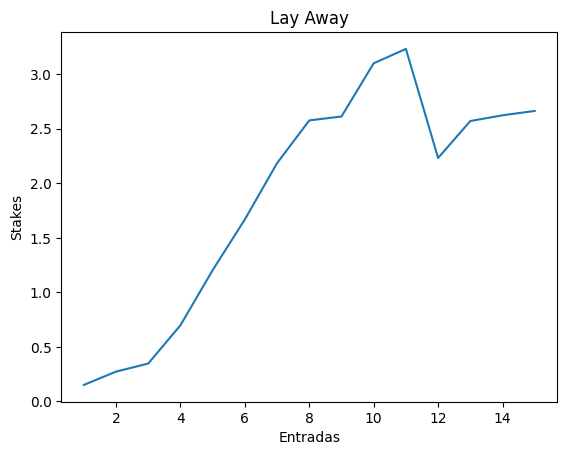

In [15]:
flt = (df_test.Odd_H_Pred < df_test.Odd_H) & (df_test.Odd_H < df_test.Odd_A)
df0 = df_test[flt]
df0 = drop_reset_index(df0)

Green = 1/(df0['Odd_A_Lay'] - 1)
Red = -1

df0['Profit'] = np.where((df0['Lay_Away'] == 1), Green, Red)
plot_profit_acu(df0,'Lay Away')

### Utilizando a Matriz de Correlação

In [16]:
features = ['VAR01','VAR02','VAR03','VAR04','VAR05','VAR06','VAR07',
            'VAR08','VAR09','VAR10','VAR11','VAR12','VAR13','VAR14',
            'VAR15','VAR16','VAR17','VAR18','VAR19','VAR20','VAR21',
            'VAR22','VAR23','VAR24','VAR25','VAR26','VAR27','VAR28',
            'VAR29','VAR30','VAR31','VAR32','VAR33','VAR34','VAR35',
            'VAR36','VAR37','VAR38','VAR39','VAR40','VAR41','VAR42',
            'VAR43','VAR44','VAR45','VAR46','VAR47','VAR48','VAR49',
            'VAR50','VAR51','VAR52','VAR53','VAR54','VAR55','VAR56',
            'VAR57','VAR58','VAR59','VAR60','VAR61','VAR62','VAR63',
            'VAR64','VAR65','VAR66','VAR67','VAR68','VAR69','VAR70',
            'VAR71','VAR72','VAR73','VAR74','VAR75','VAR76','VAR77','Lay_Away']

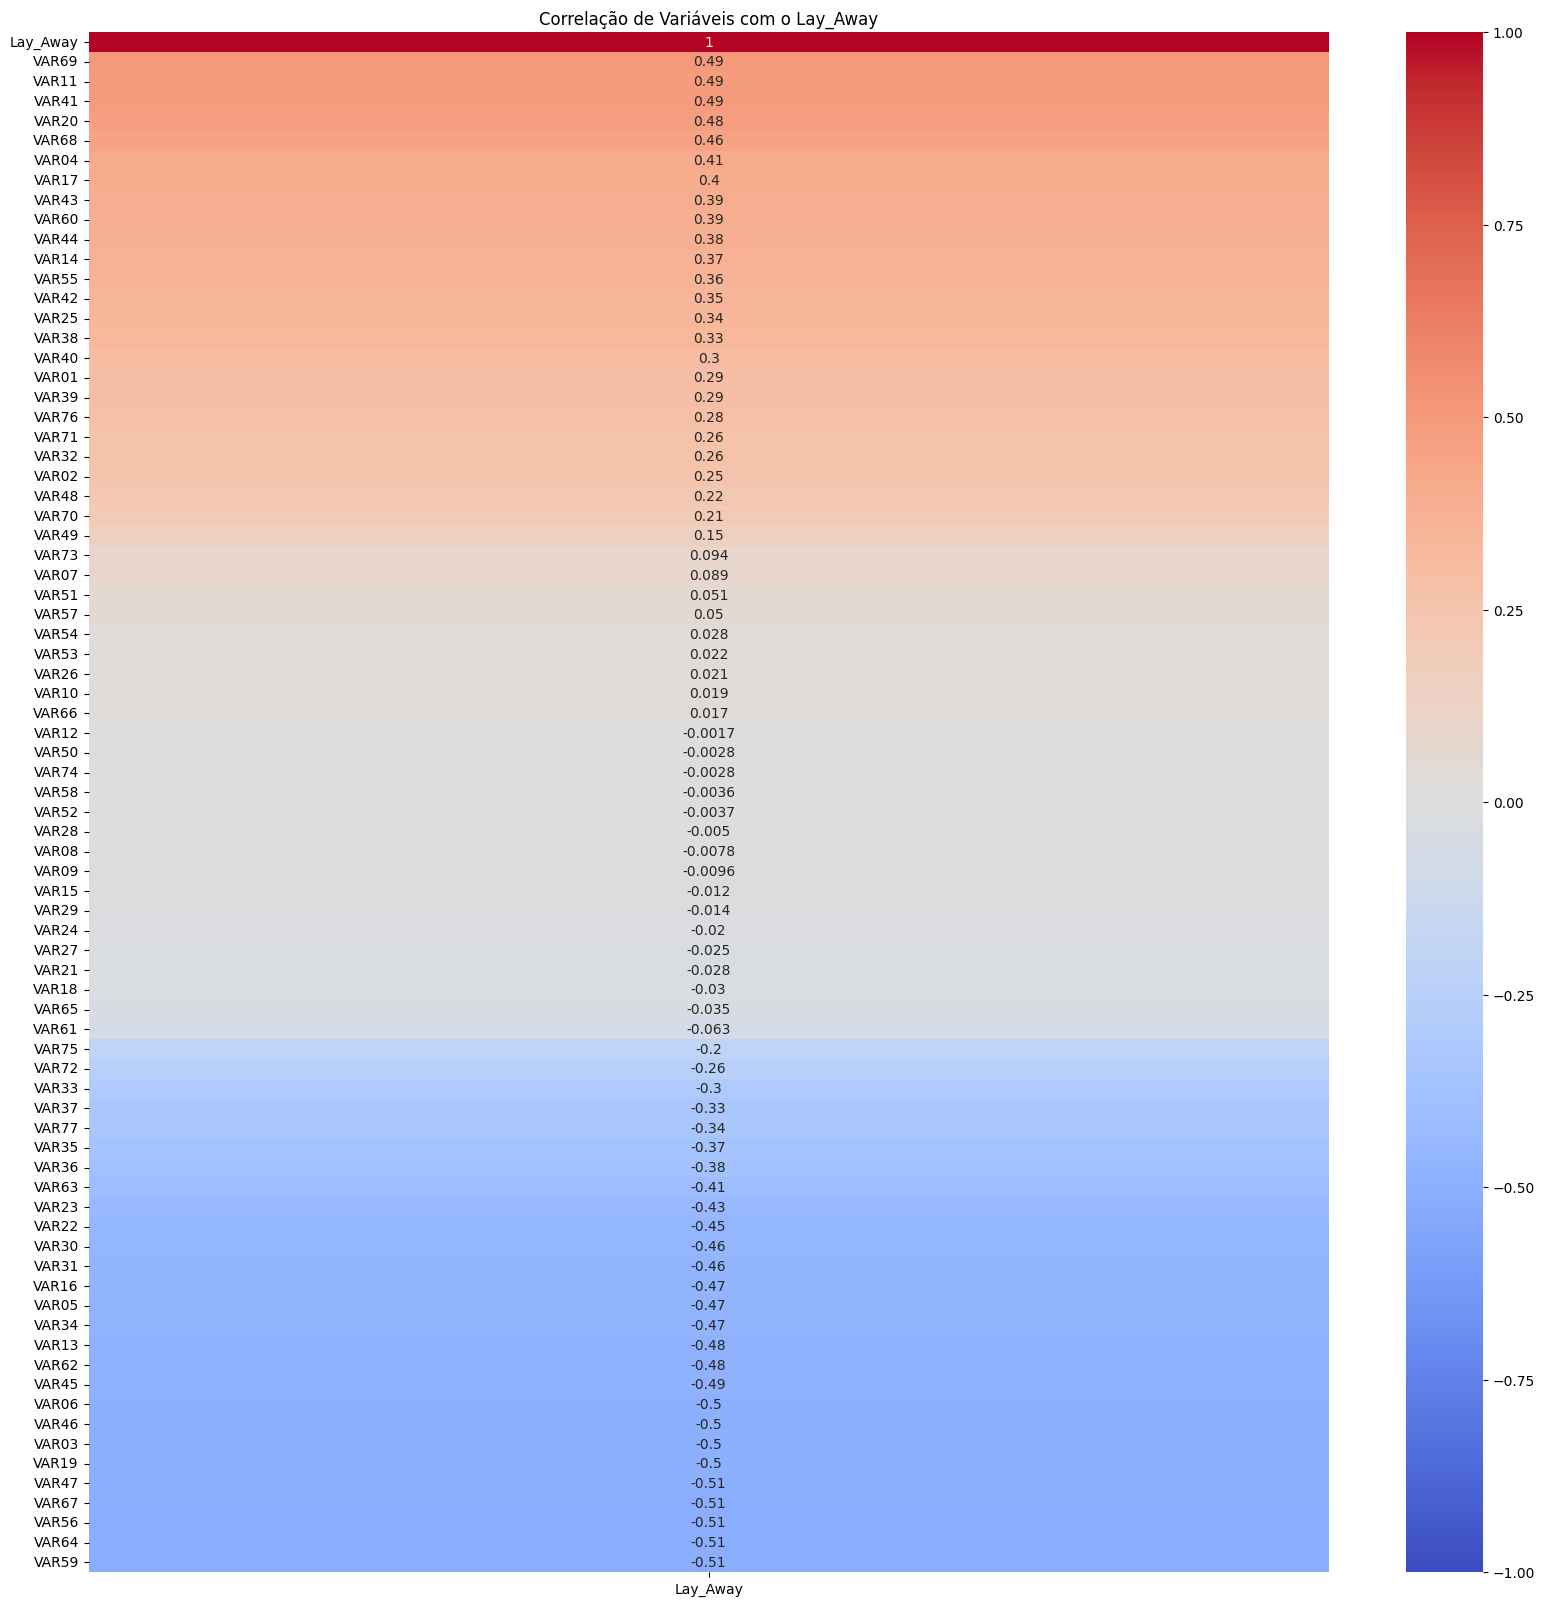

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

df0 = df[features]

correlacao = df0.corr()

plt.figure(figsize= (20,20))

sns.heatmap(correlacao[['Lay_Away']].sort_values(by='Lay_Away', ascending=False),
            annot=True,
            cmap='coolwarm',
            vmin=-1,
            vmax=1)
plt.title("Correlação de Variáveis com o Lay_Away")
plt.show()

In [18]:
tt = correlacao[['Lay_Away']].sort_values(by='Lay_Away', ascending=False)
flt = tt.Lay_Away >= 0.2
ttt = tt[flt]

var_list = ttt.index.tolist()
var_list

['Lay_Away',
 'VAR69',
 'VAR11',
 'VAR41',
 'VAR20',
 'VAR68',
 'VAR04',
 'VAR17',
 'VAR43',
 'VAR60',
 'VAR44',
 'VAR14',
 'VAR55',
 'VAR42',
 'VAR25',
 'VAR38',
 'VAR40',
 'VAR01',
 'VAR39',
 'VAR76',
 'VAR71',
 'VAR32',
 'VAR02',
 'VAR48',
 'VAR70']

In [21]:
features = ['VAR69',
 'VAR11',
 'VAR41',
 'VAR20',
 'VAR68',
 'VAR04',
 'VAR17',
 'VAR43',
 'VAR60',
 'VAR44',
 'VAR14',
 'VAR55',
 'VAR42',
 'VAR25',
 'VAR38',
 'VAR40',
 'VAR01',
 'VAR39',
 'VAR76',
 'VAR71',
 'VAR32',
 'VAR02',
 'VAR48',
 'VAR70']

Método: Lay Away
Profit: 2.32 stakes em 19 jogos
ROI: 12.19 %
Drawdown Maximo Acumulado: -1.72
Winrate Medio: 89.47 %
Desvio Padrao: 0.43



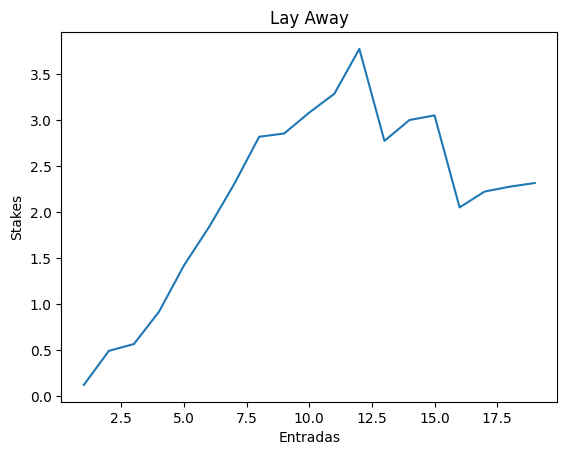

In [22]:
X_train = df_train[features]
y_train = df_train[target]

model = LinearRegression()
model.fit(X_train, y_train)

X_test = df_test[features]

Predicted_Odd = model.predict(X_test)
df_test['Odd_H_Pred'] = Predicted_Odd

flt = (df_test.Odd_H_Pred < df_test.Odd_H) & (df_test.Odd_H < df_test.Odd_A)
df0 = df_test[flt]
df0 = drop_reset_index(df0)

Green = 1/(df0['Odd_A_Lay'] - 1)
Red = -1

df0['Profit'] = np.where((df0['Lay_Away'] == 1), Green, Red)
plot_profit_acu(df0,'Lay Away')